# Phase 0.4 - Reconnaissance des donnees synthetiques (24 mois + labels de fraude)

**Proprietaire : Cherica** - tache 4 de la Phase 0 du plan d'action.

> *"Parcourir les 24 mois de donnees synthetiques et leurs labels de fraude."*

## Pourquoi cette etape existe

Avant de construire la base (Phase 1) et d'entrainer un modele (Phase 2), il faut
**comprendre les donnees** : combien de tables, sur quelle periode, quel est le
taux de fraude, quelles sont les cles qui relient les tables, et surtout quels
pieges nous attendent (valeurs manquantes, doublons, colonnes interdites,
factures invalides).

Regle a retenir : **on ne modelise jamais des donnees qu'on n'a pas d'abord
regardees.** Un schema mal concu au depart se paie pendant tout le projet.

## Ce que ce carnet produit

1. Inventaire des tables
2. Couverture temporelle (les 24 mois)
3. Les labels de fraude (taux, types)
4. Le desequilibre des classes (et pourquoi ca compte)
5. Les cles et relations entre tables
6. Les controles de qualite (doublons, dates, conventions)
7. Les colonnes de **fuite de donnees** a exclure du modele
8. Les premiers signaux discriminants
9. Le cas des factures invalides
10. La synthese et les prochaines etapes

Un carnet ne fait **jamais** partie de la chaine de production : il sert a
comprendre. Le code qui exploite les donnees vit dans les scripts de
`apps/ml-training/`.

## 1. Preparation : trouver et charger les donnees

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)

Le jeu de donnees vit **hors du depot** (dossier `CohorteAI_datagen`). On le
localise de facon robuste : on remonte les dossiers parents a la recherche du
fichier `factures.csv`. Les labels de fraude se trouvent dans le **meme**
dossier `dataset/` (et non dans un dossier `labels/` separe).

In [2]:
DOSSIER = None
for ancetre in [Path.cwd(), *Path.cwd().parents]:
    for rel in (("CohorteAI_datagen", "dataset"), ("dataset",), ("data", "raw")):
        candidat = ancetre.joinpath(*rel)
        if (candidat / "factures.csv").exists():
            DOSSIER = candidat
            break
    if DOSSIER:
        break

assert DOSSIER is not None, "factures.csv introuvable : verifie l'emplacement du jeu de donnees"

NOMS_TABLES = [
    "referentiel_actes",
    "referentiel_medicaments",
    "garanties",
    "prestataires",
    "grille_tarifaire",
    "contrats",
    "assures",
    "identites_pii",
    "ordonnances",
    "ordonnance_lignes",
    "factures",
    "lignes_facture",
    "labels_fraude",
    "labels_prestataires",
]
donnees = {
    nom: pd.read_csv(DOSSIER / f"{nom}.csv", dtype=str, keep_default_na=False, na_values=[""])
    for nom in NOMS_TABLES
    if (DOSSIER / f"{nom}.csv").exists()
}

SORTIES = Path.cwd() / "outputs_phase0_4"
SORTIES.mkdir(exist_ok=True)

print("Dossier de donnees :", DOSSIER)
print("Tables chargees    :", len(donnees))
print("Dossier de sortie  :", SORTIES)

Dossier de donnees : C:\capstone\CohorteAI_datagen\dataset
Tables chargees    : 14
Dossier de sortie  : C:\capstone\predicare\apps\ml-training\notebooks\outputs_phase0_4


## 2. Inventaire des tables

On compte les lignes et les colonnes de chaque table. Ca donne l'**ordre de
grandeur** du projet et l'ordre de chargement : les petites tables (referentiels)
avant les grandes (factures).

In [3]:
inventaire = pd.DataFrame(
    [{"table": nom, "lignes": len(df), "colonnes": df.shape[1]} for nom, df in donnees.items()]
).sort_values("lignes", ascending=False)
inventaire.to_csv(SORTIES / "inventaire.csv", index=False)
display(inventaire)
print(f"TOTAL lignes toutes tables confondues : {inventaire['lignes'].sum():,}")

,table,lignes,colonnes
11,lignes_facture,123270,9
10,factures,84593,24
12,labels_fraude,84593,6
9,ordonnance_lignes,82175,6
8,ordonnances,47804,8
7,identites_pii,4459,10
6,assures,4459,9
4,grille_tarifaire,3242,3
5,contrats,1500,12
3,prestataires,251,20


TOTAL lignes toutes tables confondues : 436,710


## 3. Couverture temporelle : les 24 mois

On regarde la date de soin. On verifie qu'on a bien ~24 mois pleins, et on
trace le volume mensuel. **C'est cette colonne de date qui servira a decouper
l'entrainement dans le temps** (Phase 2) : on entraine sur le passe, on teste
sur le futur. Un decoupage aleatoire serait une erreur.

Periode des soins : 2024-10-01 -> 2026-10-01
Mois distincts    : 25 (dont 24 mois pleins)
Factures / mois   : min=1  median=3508  max=4280
Note : 24 mois pleins (2024-10 -> 2026-09) + un mois entame (2026-10, anecdotique).


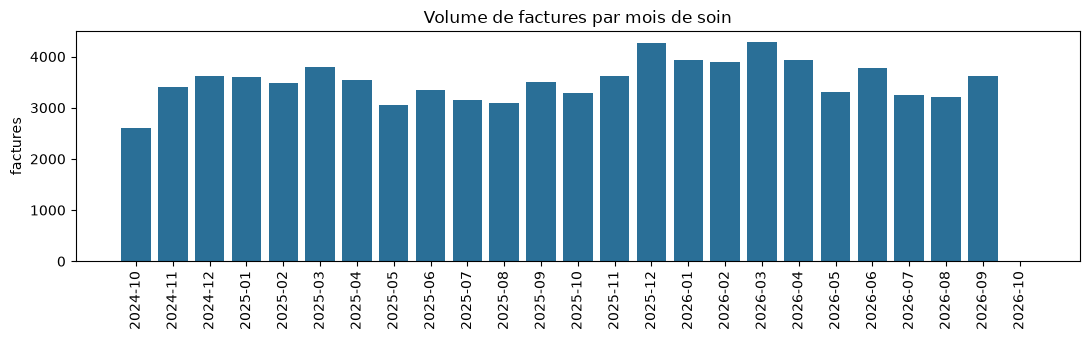

In [4]:
factures = donnees["factures"].copy()
ds = pd.to_datetime(factures["date_soin"], errors="coerce")

print("Periode des soins :", ds.min().date(), "->", ds.max().date())
mois = ds.dt.to_period("M")
compte_mois = mois.value_counts()
mois_pleins = int((compte_mois >= 100).sum())
print("Mois distincts    :", mois.nunique(), f"(dont {mois_pleins} mois pleins)")
print(
    f"Factures / mois   : min={compte_mois.min()}  median={int(compte_mois.median())}  max={compte_mois.max()}"
)
print("Note : 24 mois pleins (2024-10 -> 2026-09) + un mois entame (2026-10, anecdotique).")

par_mois = mois.value_counts().sort_index()
par_mois.index = par_mois.index.astype(str)
par_mois.to_frame("nb_factures").to_csv(SORTIES / "factures_par_mois.csv")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(par_mois.index, par_mois.values, color="#2a6f97")
ax.set_title("Volume de factures par mois de soin")
ax.set_ylabel("factures")
ax.tick_params(axis="x", rotation=90)
fig.tight_layout()
fig.savefig(SORTIES / "factures_par_mois.png", dpi=110)
plt.show()

## 4. Les labels de fraude

Tout l'apprentissage repose sur ce fichier : `est_fraude` (la cible : 0 ou 1)
et `type_fraude` (la nature de la fraude). **Sans labels, pas de modele
supervise.** On verifie qu'ils couvrent bien toutes les factures.

In [5]:
labels = donnees["labels_fraude"].copy()
labels["est_fraude"] = pd.to_numeric(labels["est_fraude"], errors="coerce").fillna(0).astype(int)
nb_fraude = int(labels["est_fraude"].sum())
taux = nb_fraude / len(labels)

print(f"Factures etiquetees : {len(labels):,}")
print(f"Fraudes             : {nb_fraude:,}   ->   taux global = {taux:.2%}")

types = (
    labels.loc[labels["est_fraude"] == 1, "type_fraude"]
    .value_counts()
    .rename_axis("type_fraude")
    .to_frame("nb")
)
types["part_des_fraudes"] = (types["nb"] / nb_fraude).round(4)
types.to_csv(SORTIES / "types_fraude.csv")
display(types)
print("Nombre de types de fraude :", types.shape[0])

Factures etiquetees : 84,593
Fraudes             : 7,347   ->   taux global = 8.69%


,nb,part_des_fraudes
type_fraude,,
SURFACTURATION,1272,0.1731
DOUBLON,909,0.1237
UPCODING,742,0.1010
LIGNES_NON_PRESCRITES,733,0.0998
QUANTITE_EXCESSIVE,568,0.0773
ORDONNANCE_EXPIREE,502,0.0683
ACTE_FICTIF,496,0.0675
SURCONSOMMATION,469,0.0638
INCOHERENCE_PROFIL,379,0.0516


Nombre de types de fraude : 14


## 5. Le desequilibre des classes

C'est un point central du CDC. La fraude est **minoritaire** (~9 %). Consequences
concretes : la metrique *accuracy* est trompeuse (un modele qui dit "jamais de
fraude" aurait 91 % d'accuracy et serait inutile) ; il faudra SMOTE **sur le seul
jeu d'entrainement**, choisir le seuil en faveur du **rappel**, et evaluer avec
rappel / precision / PR-AUC.

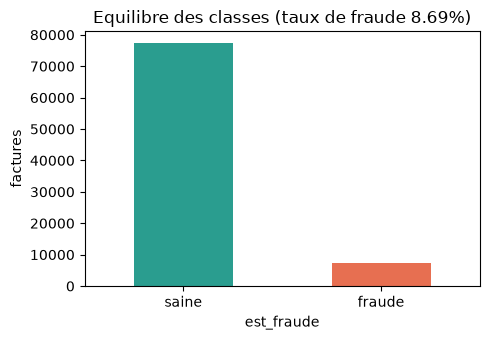

Environ 1 fraude pour 10.5 factures saines.


In [6]:
fig, ax = plt.subplots(figsize=(5, 3.5))
labels["est_fraude"].map({0: "saine", 1: "fraude"}).value_counts().plot(
    kind="bar", ax=ax, color=["#2a9d8f", "#e76f51"]
)
ax.set_title(f"Equilibre des classes (taux de fraude {taux:.2%})")
ax.set_ylabel("factures")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(SORTIES / "equilibre_classes.png", dpi=110)
plt.show()

print("Environ 1 fraude pour", round((1 - taux) / taux, 1), "factures saines.")

## 6. Cles et relations entre tables

Ici on verifie les **jointures** : chaque cle doit etre unique (pas de doublon),
et chaque identifiant reference doit exister en face (pas d'orphelin). C'est ce
qui va nous permettre de dessiner les relations (cles etrangeres) de la Phase 1.

In [7]:
cles = {
    "assures": "assure_id",
    "prestataires": "prestataire_id",
    "contrats": "contrat_id",
    "factures": "facture_id",
    "lignes_facture": "ligne_id",
    "ordonnances": "ordonnance_id",
    "identites_pii": "assure_id",
    "labels_fraude": "facture_id",
    "labels_prestataires": "prestataire_id",
}
bilan = []
for nom, cle in cles.items():
    if nom in donnees and cle in donnees[nom].columns:
        d = donnees[nom]
        bilan.append(
            {
                "table": nom,
                "cle": cle,
                "lignes": len(d),
                "valeurs_uniques": d[cle].nunique(),
                "doublons": int(d[cle].duplicated().sum()),
            }
        )
display(pd.DataFrame(bilan))

ids_factures = set(donnees["factures"]["facture_id"])
ids_labels = set(donnees["labels_fraude"]["facture_id"])
print("Factures            :", len(ids_factures))
print("Labels              :", len(ids_labels))
print("Factures sans label :", len(ids_factures - ids_labels))
print("Labels sans facture :", len(ids_labels - ids_factures))

,table,cle,lignes,valeurs_uniques,doublons
0,assures,assure_id,4459,4459,0
1,prestataires,prestataire_id,251,251,0
2,contrats,contrat_id,1500,1500,0
3,factures,facture_id,84593,84593,0
4,lignes_facture,ligne_id,123270,123270,0
5,ordonnances,ordonnance_id,47804,47804,0
6,identites_pii,assure_id,4459,4459,0
7,labels_fraude,facture_id,84593,84593,0
8,labels_prestataires,prestataire_id,251,251,0


Factures            : 84593
Labels              : 84593
Factures sans label : 0
Labels sans facture : 0


## 7. Controles de qualite

On traque les anomalies que la Phase 1.4 devra nettoyer : montants absurdes,
numeros de facture en double, incoherences de dates, soins prodiguees par un
prestataire hors convention ou radie. **On ne bloque pas** : on compte et on
journalise, pour decider ensuite.

In [8]:
controles = {}
montant = pd.to_numeric(factures["montant_total"], errors="coerce")
controles["montant_total <= 0"] = int((montant <= 0).sum())
if "numero_facture" in factures.columns:
    controles["numero_facture duplique"] = int(factures["numero_facture"].duplicated().sum())

date_fact = pd.to_datetime(factures["date_facture"], errors="coerce")
controles["soin apres la facture"] = int((ds > date_fact).sum())

presta = donnees["prestataires"].copy()
presta["date_fin_convention"] = pd.to_datetime(presta["date_fin_convention"], errors="coerce")
presta = presta.rename(columns={"statut": "statut_prestataire"})
joint = factures.merge(
    presta[["prestataire_id", "date_fin_convention", "statut_prestataire"]],
    on="prestataire_id",
    how="left",
)
controles["soin apres fin de convention"] = int(
    (pd.to_datetime(joint["date_soin"]) > joint["date_fin_convention"]).sum()
)
controles["facture d'un prestataire radie"] = int((joint["statut_prestataire"] == "RADIE").sum())

qualite = pd.DataFrame(list(controles.items()), columns=["controle", "nb_factures"])
qualite["part"] = (qualite["nb_factures"] / len(factures)).round(5)
qualite.to_csv(SORTIES / "controles_qualite.csv", index=False)
display(qualite)

,controle,nb_factures,part
0,montant_total <= 0,0,0.00000
1,numero_facture duplique,553,0.00654
2,soin apres la facture,0,0.00000
3,soin apres fin de convention,157,0.00186
4,facture d'un prestataire radie,3063,0.03621


## 8. La fuite de donnees (le piege a eviter absolument)

Certaines colonnes viennent du **traitement humain de la facture** (le
gestionnaire a paye, rejete, motive son rejet...). Les utiliser comme variables
serait de la **triche** : le modele apprendrait la decision passee au lieu de
detecter la fraude. Le dictionnaire des donnees interdit ces 4 colonnes :

`statut`, `motif_rejet`, `montant_pris_en_charge`, `date_traitement`

On le prouve : le taux de fraude explose selon ces colonnes.

In [9]:
COLS_FUITE = ["statut", "motif_rejet", "montant_pris_en_charge", "date_traitement"]

tableau = factures.copy()
tableau["est_fraude"] = (
    tableau["facture_id"]
    .map(dict(zip(labels["facture_id"], labels["est_fraude"], strict=True)))
    .fillna(0)
    .astype(int)
)
for colonne in COLS_FUITE:
    if colonne in tableau.columns:
        moyenne = (
            tableau.groupby(colonne, dropna=False)["est_fraude"]
            .agg(nb_factures="count", taux_fraude="mean")
            .round(4)
        )
        print(f"--- est_fraude selon {colonne} ---")
        display(moyenne)

--- est_fraude selon statut ---


,nb_factures,taux_fraude
statut,,
EN_COURS,2826,0.0881
PAYEE,79775,0.0716
REJETEE,1992,0.6973


--- est_fraude selon motif_rejet ---


,nb_factures,taux_fraude
motif_rejet,,
CONTROLE_MEDICAL,998,1.0000
DELAI_DE_CARENCE,151,0.1325
ENTENTE_PREALABLE_ABSENTE,15,0.6000
HORS_PERIODE_COUVERTURE,69,1.0000
ORDONNANCE_PERIMEE,246,1.0000
PIECE_MANQUANTE_ATTESTATION,459,0.0588
PLAFOND_ATTEINT,51,0.3333
PRODUIT_NON_REMBOURSABLE,3,1.0000
NaN,82601,0.0721


--- est_fraude selon montant_pris_en_charge ---


,nb_factures,taux_fraude
montant_pris_en_charge,,
0,4818,0.3400
1000,4,0.0000
10000,153,0.0392
100000,7,0.2857
1000700,1,0.0000
...,...,...
9960,3,1.0000
99600,7,0.0000
9980,2,1.0000


--- est_fraude selon date_traitement ---


,nb_factures,taux_fraude
date_traitement,,
2024-10-06,1,0.0000
2024-10-07,2,0.0000
2024-10-08,3,0.0000
2024-10-09,2,0.0000
2024-10-10,6,0.1667
...,...,...
2026-09-30,29,0.0000
2026-10-01,28,0.0000
2026-10-02,13,0.0000


## 9. Premiers signaux discriminants

Sans rien modeliser encore, on regarde quel est le taux de fraude selon quelques
dimensions metier. Ces observations alimenteront directement le *feature
engineering* (Phase 2.2) : agregation par prestataire, par acte, par assure.

In [10]:
def taux_par(df, colonne, mini=1):
    g = df.groupby(colonne)["est_fraude"].agg(
        nb_factures="count", nb_fraudes="sum", taux_fraude="mean"
    )
    return g[g["nb_factures"] >= mini].sort_values("taux_fraude", ascending=False).round(4)


print("Taux de fraude par type de facture :")
display(taux_par(tableau, "type_facture"))

top_prestataires = taux_par(tableau, "prestataire_id", mini=50).head(10)
top_prestataires.to_csv(SORTIES / "top_prestataires_fraude.csv")
print("Top 10 prestataires (au moins 50 factures) :")
display(top_prestataires)

Taux de fraude par type de facture :


,nb_factures,nb_fraudes,taux_fraude
type_facture,,,
KINESITHERAPIE,789,193,0.2446
MATERNITE,766,157,0.2050
OPTIQUE,546,91,0.1667
DENTAIRE,1966,283,0.1439
HOSPITALISATION,513,60,0.1170
IMAGERIE,2611,304,0.1164
PHARMACIE,32488,3087,0.0950
LABORATOIRE,10306,970,0.0941
CONSULTATION,34608,2202,0.0636


Top 10 prestataires (au moins 50 factures) :


,nb_factures,nb_fraudes,taux_fraude
prestataire_id,,,
PRE-00211,196,118,0.6020
PRE-00162,1186,512,0.4317
PRE-00155,1443,530,0.3673
PRE-00037,296,103,0.3480
PRE-00073,227,57,0.2511
PRE-00093,911,226,0.2481
PRE-00183,159,34,0.2138
PRE-00086,444,94,0.2117
PRE-00208,87,18,0.2069


## 10. Le cas des factures invalides

Le CDC precise que le jury teste 20 factures **inedites**, dont des factures
invalides le jour J. Or dans ce jeu de donnees, **aucune facture etiquetee
n'est invalide** : le rejet des factures invalides ne pourra donc **pas** venir
du modele. Il sera fait par des **regles deterministes** de validation (Phase 3.2).

In [11]:
etiquettes = donnees["labels_fraude"]
invalides = pd.to_numeric(etiquettes["est_valide"], errors="coerce")
print("Factures marquees est_valide == 0 :", int((invalides == 0).sum()))
print(
    "Factures avec un motif_invalidite :",
    int((etiquettes["motif_invalidite"].fillna("").str.strip() != "").sum()),
)
print("=> Aucune facture invalide etiquetee : le rejet se fera par regles deterministes.")

Factures marquees est_valide == 0 : 0
Factures avec un motif_invalidite : 0
=> Aucune facture invalide etiquetee : le rejet se fera par regles deterministes.


## 11. Synthese de la Phase 0.4

Ce que l'on retient, et ce que ca implique pour la suite.

In [12]:
synthese = f"""# Phase 0.4 - Reconnaissance des donnees (proprietaire : Cherica)

- Tables analysees : {len(donnees)}
- Lignes totales : {inventaire["lignes"].sum():,}
- Periode couverte : {ds.min().date()} -> {ds.max().date()} ({mois_pleins} mois pleins + {mois.nunique() - mois_pleins} mois entame)
- Factures : {len(labels):,} | Fraudes : {nb_fraude:,} ({taux:.2%})
- Types de fraude : {types.shape[0]}
- Desequilibre : ~1 fraude pour {round((1 - taux) / taux, 1)} factures saines -> metriques rappel/precision, SMOTE sur train seulement
- Colonnes de fuite a exclure : {", ".join(COLS_FUITE)}
- Factures invalides etiquetees : 0 -> rejet par regles deterministes (Phase 3)

## Prochaines etapes
- Phase 1.1 : migrations Alembic (schema cible)
- Phase 1.2 : script de chargement initial
- Phase 1.3 : pseudonymisation + table d'identites chiffree
- Phase 1.4 : nettoyage et validation (doublons, dates, conventions)
"""
(SORTIES / "rapport_phase0_4.md").write_text(synthese, encoding="utf-8")
print(synthese)
print("Fichiers produits dans", SORTIES, ":")
for p in sorted(SORTIES.iterdir()):
    print("  -", p.name)

# Phase 0.4 - Reconnaissance des donnees (proprietaire : Cherica)

- Tables analysees : 14
- Lignes totales : 436,710
- Periode couverte : 2024-10-01 -> 2026-10-01 (24 mois pleins + 1 mois entame)
- Factures : 84,593 | Fraudes : 7,347 (8.69%)
- Types de fraude : 14
- Desequilibre : ~1 fraude pour 10.5 factures saines -> metriques rappel/precision, SMOTE sur train seulement
- Colonnes de fuite a exclure : statut, motif_rejet, montant_pris_en_charge, date_traitement
- Factures invalides etiquetees : 0 -> rejet par regles deterministes (Phase 3)

## Prochaines etapes
- Phase 1.1 : migrations Alembic (schema cible)
- Phase 1.2 : script de chargement initial
- Phase 1.3 : pseudonymisation + table d'identites chiffree
- Phase 1.4 : nettoyage et validation (doublons, dates, conventions)

Fichiers produits dans C:\capstone\predicare\apps\ml-training\notebooks\outputs_phase0_4 :
  - controles_qualite.csv
  - equilibre_classes.png
  - factures_par_mois.csv
  - factures_par_mois.png
  - inventair